In [1]:
!pip install retina-face torch torchvision opencv-python

In [5]:
import cv2
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from retinaface import RetinaFace
from torchvision import transforms
from torchvision.models import mobilenet_v3_large

In [6]:
model = mobilenet_v3_large(weights=None)

# change classifier for 2 classes
model.classifier[3] = nn.Linear(model.classifier[3].in_features, 2)

model.load_state_dict(torch.load("gender_mobilenetv3_model.pth", map_location=device))

model = model.to(device)
model.eval()

MobileNetV3(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
      (2): Hardswish()
    )
    (1): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (1): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
        )
      )
    )
    (2): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 64, kernel_size=(1, 1), stride=(1, 1), bi

In [7]:
classes = ["Female","Male"]

In [8]:
transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485,0.456,0.406],
        [0.229,0.224,0.225]
    )
])

In [21]:
image_path = "WhatsApp Image 2024-05-18 at 10.44.47_6340eb8e.jpg"

img = cv2.imread(image_path)

In [22]:
faces = RetinaFace.detect_faces(image_path)

print(faces)

{'face_1': {'score': np.float64(0.9997309446334839), 'facial_area': [np.int64(968), np.int64(153), np.int64(1072), np.int64(277)], 'landmarks': {'right_eye': [np.float32(982.6085), np.float32(203.06442)], 'left_eye': [np.float32(1027.4418), np.float32(202.49083)], 'nose': [np.float32(995.23145), np.float32(226.7538)], 'mouth_right': [np.float32(986.3252), np.float32(246.13759)], 'mouth_left': [np.float32(1024.973), np.float32(245.61876)]}}, 'face_2': {'score': np.float64(0.999674916267395), 'facial_area': [np.int64(579), np.int64(146), np.int64(666), np.int64(252)], 'landmarks': {'right_eye': [np.float32(612.4858), np.float32(181.23672)], 'left_eye': [np.float32(651.9393), np.float32(185.54756)], 'nose': [np.float32(634.8163), np.float32(207.00186)], 'mouth_right': [np.float32(612.2223), np.float32(224.38759)], 'mouth_left': [np.float32(642.84515), np.float32(227.82695)]}}, 'face_3': {'score': np.float64(0.9995504021644592), 'facial_area': [np.int64(509), np.int64(57), np.int64(577), n

In [23]:
for key in faces:

    x1,y1,x2,y2 = faces[key]['facial_area']

    face = img[y1:y2, x1:x2]

    face = cv2.cvtColor(face, cv2.COLOR_BGR2RGB)

    face = transform(face).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(face)
        _,pred = torch.max(output,1)

    gender = classes[pred.item()]

    cv2.rectangle(img,(x1,y1),(x2,y2),(0,255,0),2)

    cv2.putText(img,
                gender,
                (x1,y1-10),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.8,
                (0,255,0),
                2)

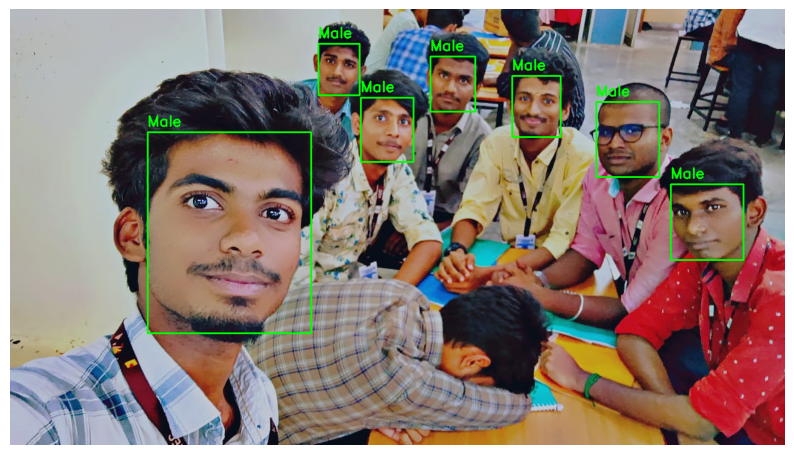

In [24]:
plt.figure(figsize=(10,8))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()